# 06 · Evaluación integrada, robustez y utilidad pública (Paso 10)

**Propósito.** Evaluar el sistema como **ayuda para la priorización territorial**, no como tres ejercicios aislados. Se busca establecer cuándo supera al historial, cuándo no, y qué decisiones puede informar razonablemente. **Informe:** [docs/robustness_report.md](../docs/robustness_report.md).

| Bloque | Datos | Uso del test 2025 |
|---|---|---|
| §1–§2 Cobertura top-K (H5) | Modelos **congelados** de los Pasos 07 y 08, reajustados por *fold* con sus configuraciones fijas | Sí, con los modelos ya seleccionados. Es la evaluación integrada prevista en el protocolo |
| §3 Sensibilidades (K, empates, pandemia, composición, latencia, V2024) | **Solo validación** 2022–2024 | No |
| §4 Escala (H7) | Desarrollo 2019–2024, rankings sin ajuste | No |
| §5 Sesgos territoriales e incertidumbre | Predicciones de test ya guardadas (Pasos 07 y 08) | Descriptivo, sin nuevas decisiones |
| §6 Exposición por corredor (H8) | Conteos de 2024 y hechos de 2024 | No |

Ninguna configuración se vuelve a seleccionar en este notebook.

### Guía para el lector

**La pregunta, en una frase.** Como herramienta para decidir qué barrios atender cada mes, ¿los modelos de los notebooks 03 y 04 superan al historial? ¿Qué tan firme es la respuesta y a quién podría dejar afuera?

**La medida central: cobertura.** Si cada mes se atienden K barrios, la cobertura es la proporción de los hechos del mes siguiente que ocurrió en esos barrios. Por ejemplo, 43 % con K = 10: 10 de 48 barrios (el 21 %) reúnen el 43 % de los siniestros.

**Las cinco estrategias que se comparan.** El clasificador del 04, la regresión del 03, el **historial** (promedio de 12 meses; es la referencia), un **oráculo** que conoce el resultado (el máximo posible) y el **azar** (K/48).

**Cómo está organizado.** §1–§2 cobertura con los modelos congelados; §3 sensibilidades; §4 escala de análisis; §5 sesgos territoriales; §6 exposición al tránsito. **Ninguna configuración se vuelve a elegir aquí.**

**Resultados principales.**
- **Con 10 barrios**, el historial cubre el **42,7 %** de los hechos de 2025, el oráculo el 44,6 % y el azar el 20,8 %. El historial ya obtiene alrededor del **92 % de la ganancia posible** sobre el azar. El clasificador agrega +0,3 puntos, una diferencia no concluyente.
- **Las sensibilidades** (otros K, desempates, pandemia, demora de publicación y 2024 como prueba alternativa) llevan a la misma conclusión.
- **La escala barrio × mes es un buen punto intermedio** entre unidades más finas, más ruidosas, y más gruesas, menos concentradas.
- **Sesgo del criterio.** Los barrios del borde tienen el 16 % de los hechos, pero reciben el 8 % (clasificador) o el 10 % (historial) de las selecciones: su carga está repartida entre barrios de volumen medio y solo Saavedra entra con regularidad al top 10.
- **Exposición (resultado indicativo).** En los corredores con medición de tránsito, ordenar por tasa por vehículo en lugar de por conteo cambia de cuartil al 43 % de los puntos. Cada sensor mide un solo sentido de circulación, así que el denominador no es del todo comparable entre sensores: no es una medición de riesgo (revisión independiente, R1).

### Glosario de este notebook

| Término | Significado |
|---|---|
| **Cobertura (top-K)** | Proporción de los hechos del mes siguiente que ocurre en los K barrios elegidos. |
| **K** | Cantidad de barrios priorizados: 5, 10 o 15. |
| **Oráculo** | Elige después de conocer los hechos reales. Marca el máximo alcanzable, no es un pronóstico. |
| **Azar esperado** | K/48: cobertura media si se eligieran barrios al azar. |
| **Ganancia sobre el azar (92 %)** | (cobertura del historial − azar) / (cobertura del oráculo − azar), con K = 10. No es el porcentaje de hechos cubiertos. |
| **pp** | Puntos porcentuales: diferencia entre dos porcentajes. |
| **IC por bloques** | Incertidumbre entre meses (bloques de 3 meses). Si incluye el 0, la diferencia no es concluyente. |
| **Intervalo pareado de desempate** | Variación de un resultado al repetir el desempate con distintas semillas: 500 en validación y 200 en el test de 2025. |
| **R0; R-incl; R-excl-empates** | Formas de definir el top 10 cuando hay empates en el puesto 10 (notebook 00, §8.1). |
| ***Gap* = 1; V2024** | Un mes más de demora en la publicación; usar 2024 como prueba alternativa si los datos de 2025 son provisorios. |
| **Error relativo** | MAE dividido por la media de hechos del barrio; permite comparar barrios grandes y chicos. |
| **Tasa por millón de vehículos** (`tasa_por_millon_veh`) | Hechos de 2024 a 150 m de un sensor por cada millón de vehículos registrados en el año (media diaria × 365). Cada sensor cuenta un solo sentido de circulación: es una aproximación indicativa a la exposición, no un riesgo comparable entre sensores. |
| **H5; H7; H8** | Hipótesis de la propuesta: utilidad de la priorización top-K, dependencia de la escala y efecto de ajustar por exposición. |

## 0. Datos, modelos congelados y predicciones

> **Qué hace la celda siguiente.** Recupera las configuraciones congeladas de los notebooks 03 y 04 y las reentrena en cada año de validación y en el ajuste final, sin elegir nada nuevo. **Qué mirar en la salida:** el reentrenamiento reproduce las cifras guardadas del notebook 04 (0,7694, 0,8292 y 0,7861), lo que confirma que se evalúan los mismos modelos.

In [1]:
import json, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import geopandas as gpd
import shapely
import matplotlib.pyplot as plt
from scipy import stats
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
import sys; sys.path.insert(0, str(ROOT))
from src import features as F, regression as R, classification as Cl
from src.evaluation import topk_coverage, block_bootstrap_ci
from src.labels import top_k_labels, inclusion_prob
from src.data_processing import CRS_CABA
warnings.filterwarnings("ignore")
FIG, TAB = ROOT / "reports" / "figures" / "06_integrated_evaluation", ROOT / "reports" / "tables" / "06_integrated_evaluation"
FIG.mkdir(parents=True, exist_ok=True); TAB.mkdir(parents=True, exist_ok=True)
SURFACE, INK, INK2, GRID = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df"
CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE, "axes.edgecolor": GRID,
                     "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": GRID,
                     "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True, "font.size": 10})
SEED = 20261110; M = {}
panel = F.load_panel(); nbrs = F.queen_neighbors()
X = R.add_log_features(F.build_features(panel, nbrs, h=1, gap=0)); folds = F.temporal_folds(X); tr_fin, te_fin = F.final_split(X)
sel_reg = json.loads((ROOT / "reports/tables/03_regression/seleccion_congelada.json").read_text(encoding="utf-8"))
sel_clf = json.loads((ROOT / "reports/tables/04_classification/seleccion_congelada.json").read_text(encoding="utf-8"))
kr, pr = sel_reg["familia"], sel_reg["params"]; kc, pc = sel_clf["familia"], sel_clf["params"]
print("Regresión congelada:", sel_reg["modelo_seleccionado"]); print("Clasificación congelada:", sel_clf["modelo_seleccionado"])
# Validación: reajuste por fold con las configuraciones congeladas (deterministas)
parts = []
for fo in folds:
    trr = R.train_mask_excluding_pandemia(X, fo["train"], pr["excluir_pandemia"]); trc = R.train_mask_excluding_pandemia(X, fo["train"], pc["excluir_pandemia"])
    v = X.loc[fo["val"], ["barrio", "mes_objetivo", "y_target", "top10_target", "y_lag1", "y_ma12"]].copy(); v["fold"] = fo["fold"]
    v["regresion"] = R.make_model(kr, pr).fit(X.loc[trr], X.loc[trr, "y_target"]).predict(X.loc[fo["val"]])
    v["clasificador"] = Cl.make_model(kc, pc).fit(X.loc[trc], X.loc[trc, "top10_target"].astype(int)).predict_proba(X.loc[fo["val"]])[:, 1]
    parts.append(v)
VAL = pd.concat(parts, ignore_index=True)
# Test: predicciones guardadas por los Pasos 07 y 08 (no se reajusta nada)
pr_t = pd.read_csv(ROOT / "reports/tables/03_regression/predicciones_test.csv"); pc_t = pd.read_csv(ROOT / "reports/tables/04_classification/predicciones_test.csv")
TEST = pr_t[["barrio", "mes_objetivo", "y_target", "y_lag1", "y_ma12", sel_reg["modelo_seleccionado"]]].rename(columns={sel_reg["modelo_seleccionado"]: "regresion"}).merge(
    pc_t[["barrio", "mes_objetivo", "top10_target", sel_clf["modelo_seleccionado"]]].rename(columns={sel_clf["modelo_seleccionado"]: "clasificador"}), on=["barrio", "mes_objetivo"])
TEST["mes_objetivo"] = pd.PeriodIndex(TEST["mes_objetivo"], freq="M"); TEST["fold"] = "TEST2025"
assert len(TEST) == 576 and TEST["mes_objetivo"].nunique() == 12
# Control: la validación reajustada reproduce las métricas guardadas en el Paso 08
chk = VAL.groupby("fold").apply(lambda d: Cl.expected_precision_at_k(d, "clasificador").mean())
saved = pd.read_csv(ROOT / "reports/tables/04_classification/grilla_validacion.csv").set_index("modelo").loc[sel_clf["modelo_seleccionado"], ["V2022", "V2023", "V2024"]]
assert np.allclose(chk.values, saved.values.astype(float)), (chk, saved)
print("Reajuste por fold reproduce la P@10 esperada guardada del Paso 08:", chk.round(4).to_dict())

Regresión congelada: poisson|conjunto=compacto,alpha=0.1,excluir_pandemia=True
Clasificación congelada: logit|C=0.01,class_weight=None,excluir_pandemia=True


Reajuste por fold reproduce la P@10 esperada guardada del Paso 08: {'V2022': 0.7694, 'V2023': 0.8292, 'V2024': 0.7861}


## 1. Cobertura de los siniestros futuros en las K zonas priorizadas (H5)

**Cobertura** = proporción de los hechos del mes siguiente que ocurren en los K barrios seleccionados.

| Estrategia | Ordena los barrios por |
|---|---|
| Clasificador congelado (Paso 08) | Probabilidad de estar en el top 10 |
| Regresión congelada (Paso 07) | Conteo predicho |
| **Historial** (la referencia) | Media de 12 meses y persistencia |
| Oráculo (cota superior) | Hechos reales del mes |
| Azar | Valor esperado K/48 |

Se informan K = 5, 10 y 15 en cada *fold* de validación y en el test 2025.

> **Qué hace la celda siguiente.** Calcula la cobertura de cada estrategia para K = 5, 10 y 15 en los tres años de validación y en 2025. **Qué mirar en la salida:** con K = 10, la fila del historial (`historial_media12`) frente a las del oráculo y el azar.

In [2]:
STRATS = {"clasificador": "clasificador", "regresion": "regresion", "historial_media12": "y_ma12", "historial_persistencia": "y_lag1", "oraculo": "y_target"}
rows = []
for K in (5, 10, 15):
    for name, D in [*[(f, VAL[VAL["fold"] == f]) for f in ["V2022", "V2023", "V2024"]], ("TEST2025", TEST)]:
        for s, col in STRATS.items():
            rows.append({"K": K, "conjunto": name, "estrategia": s, "cobertura": float(topk_coverage(D, col, K).mean())})
        rows.append({"K": K, "conjunto": name, "estrategia": "azar_esperado", "cobertura": K / 48})
cov = pd.DataFrame(rows); cov.to_csv(TAB / "cobertura_topk.csv", index=False)
tab = cov.pivot_table(index=["K", "estrategia"], columns="conjunto", values="cobertura").round(4)
tab["val_media"] = tab[["V2022", "V2023", "V2024"]].mean(axis=1).round(4)
M["cobertura"] = tab.reset_index().to_dict(orient="records"); tab

conjunto                   TEST2025   V2022   V2023   V2024  val_media
K  estrategia                                                         
5  azar_esperado             0.1042  0.1042  0.1042  0.1042     0.1042
   clasificador              0.2646  0.2733  0.2501  0.2691     0.2642
   historial_media12         0.2644  0.2733  0.2535  0.2691     0.2653
   historial_persistencia    0.2560  0.2692  0.2397  0.2665     0.2585
   oraculo                   0.2733  0.2819  0.2622  0.2777     0.2739
   regresion                 0.2647  0.2733  0.2527  0.2691     0.2650
10 azar_esperado             0.2083  0.2083  0.2083  0.2083     0.2083
   clasificador              0.4305  0.4323  0.4197  0.4333     0.4284
   historial_media12         0.4273  0.4307  0.4174  0.4319     0.4267
   historial_persistencia    0.4217  0.4312  0.4021  0.4262     0.4198
   oraculo                   0.4462  0.4565  0.4308  0.4477     0.4450
   regresion                 0.4284  0.4313  0.4163  0.4326     0.4267
15 azar_esperado             0.3125  0.3125  0.3125  0.3125     0.3125
   clasificador              0.5523  0.5698  0.5460  0.5599     0.5586
   historial_media12         0.5566  0.5692  0.5468  0.5605     0.5588
   historial_persistencia    0.5555  0.5523  0.5363  0.5502     0.5463
   oraculo                   0.5837  0.5924  0.5685  0.5829     0.5813
   regresion                 0.5575  0.5708  0.5478  0.5607     0.5598

> **Qué hace la celda siguiente.** Calcula la diferencia de cobertura de cada modelo frente al historial, con su incertidumbre entre meses (bloques) y su sensibilidad al desempate (en esta celda, 200 semillas para el test; la función usa 500 por defecto).

In [3]:
# Diferencias frente al historial (media de 12 meses): por fold, IC por bloques en test y sensibilidad pareada al desempate
def tie_cov(D, a, b, K, seeds=500):
    d = [(topk_coverage(D, a, K, seed=SEED + 7000 + s) - topk_coverage(D, b, K, seed=SEED + 7000 + s)).mean() for s in range(seeds)]
    return float(np.quantile(d, .025)), float(np.quantile(d, .975))
rows = []
for K in (5, 10, 15):
    for s in ["clasificador", "regresion"]:
        dv = {f: float((topk_coverage(VAL[VAL["fold"] == f], s, K) - topk_coverage(VAL[VAL["fold"] == f], "y_ma12", K)).mean()) for f in ["V2022", "V2023", "V2024"]}
        dt = topk_coverage(TEST, s, K) - topk_coverage(TEST, "y_ma12", K)
        b = block_bootstrap_ci(dt); lo, hi = tie_cov(TEST, s, "y_ma12", K, seeds=200)
        rows.append({"K": K, "estrategia": s, **{f"d_{f}": v for f, v in dv.items()}, "d_val_media": np.mean(list(dv.values())),
                     "folds_positivos": int(sum(v > 0 for v in dv.values())), "d_test": b["media"], "ic_bloques_inf": b["ic_inf"], "ic_bloques_sup": b["ic_sup"],
                     "desempate_p2.5": lo, "desempate_p97.5": hi})
dif = pd.DataFrame(rows); dif.to_csv(TAB / "cobertura_diferencias_vs_historial.csv", index=False)
M["cobertura_diferencias"] = dif.round(4).to_dict(orient="records"); dif.round(4)

,K,estrategia,d_V2022,d_V2023,d_V2024,d_val_media,folds_positivos,d_test,ic_bloques_inf,ic_bloques_sup,desempate_p2.5,desempate_p97.5
0,5,clasificador,0.0000,-0.0034,0.0000,-0.0011,0,0.0002,-0.0005,0.0010,0.0002,0.0002
1,5,regresion,0.0000,-0.0008,0.0000,-0.0003,0,0.0003,0.0000,0.0010,0.0003,0.0003
2,10,clasificador,0.0016,0.0023,0.0013,0.0017,3,0.0032,-0.0007,0.0080,0.0032,0.0037
3,10,regresion,0.0006,-0.0011,0.0006,0.0000,2,0.0011,-0.0003,0.0043,0.0011,0.0016
4,15,clasificador,0.0007,-0.0008,-0.0006,-0.0002,1,-0.0043,-0.0084,-0.0015,-0.0043,-0.0038
5,15,regresion,0.0016,0.0010,0.0002,0.0009,3,0.0009,-0.0031,0.0037,0.0009,0.0014


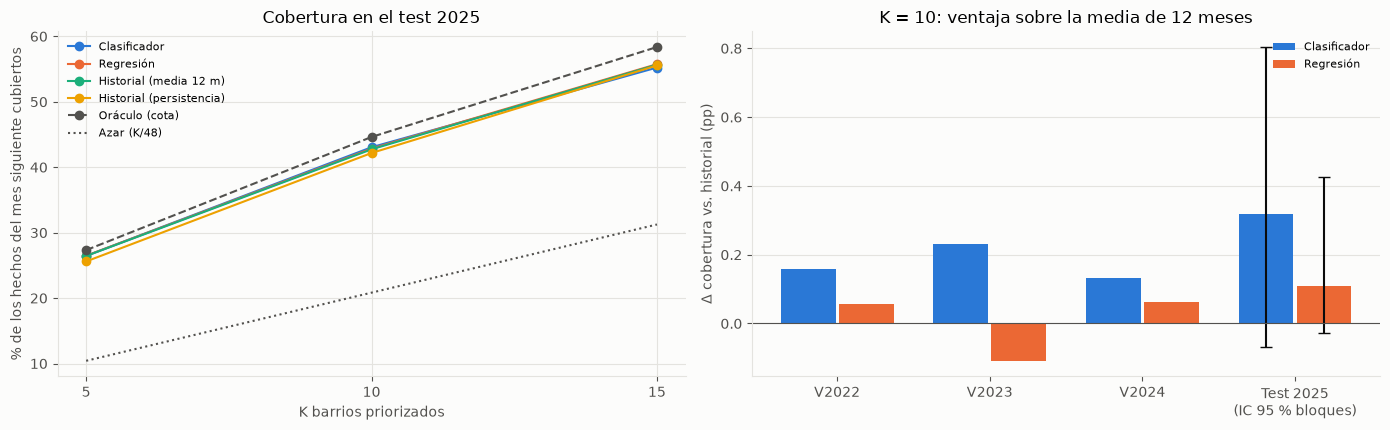

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
labs = {"clasificador": "Clasificador", "regresion": "Regresión", "historial_media12": "Historial (media 12 m)", "historial_persistencia": "Historial (persistencia)", "oraculo": "Oráculo (cota)"}
for i, s in enumerate(labs):
    d = cov[(cov["conjunto"] == "TEST2025") & (cov["estrategia"] == s)]
    axes[0].plot(d["K"], d["cobertura"] * 100, marker="o", ms=6, color=CAT[i] if s != "oraculo" else INK2, ls="--" if s == "oraculo" else "-", label=labs[s])
axes[0].plot([5, 10, 15], [5 / 48 * 100, 10 / 48 * 100, 15 / 48 * 100], color=INK2, ls=":", label="Azar (K/48)")
axes[0].set_xticks([5, 10, 15]); axes[0].set_xlabel("K barrios priorizados"); axes[0].set_ylabel("% de los hechos del mes siguiente cubiertos")
axes[0].set_title("Cobertura en el test 2025"); axes[0].legend(frameon=False, fontsize=8)
d10 = dif[dif["K"] == 10].set_index("estrategia")
xs = np.arange(4); names = ["d_V2022", "d_V2023", "d_V2024", "d_test"]
for j, s in enumerate(["clasificador", "regresion"]):
    axes[1].bar(xs + (j - .5) * .38, d10.loc[s, names] * 100, width=.36, color=CAT[j], label=labs[s])
axes[1].errorbar(3 - .19, d10.loc["clasificador", "d_test"] * 100, yerr=[[ (d10.loc["clasificador", "d_test"] - d10.loc["clasificador", "ic_bloques_inf"]) * 100], [(d10.loc["clasificador", "ic_bloques_sup"] - d10.loc["clasificador", "d_test"]) * 100]], color=INK, capsize=4)
axes[1].errorbar(3 + .19, d10.loc["regresion", "d_test"] * 100, yerr=[[ (d10.loc["regresion", "d_test"] - d10.loc["regresion", "ic_bloques_inf"]) * 100], [(d10.loc["regresion", "ic_bloques_sup"] - d10.loc["regresion", "d_test"]) * 100]], color=INK, capsize=4)
axes[1].axhline(0, color=INK2, lw=.8); axes[1].set_xticks(xs, ["V2022", "V2023", "V2024", "Test 2025\n(IC 95 % bloques)"])
axes[1].set_ylabel("Δ cobertura vs. historial (pp)"); axes[1].set_title("K = 10: ventaja sobre la media de 12 meses"); axes[1].legend(frameon=False, fontsize=8); axes[1].grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG / "cobertura_topk.png", dpi=150); plt.show()

**Lectura (1): el historial ya está muy cerca del techo.**
- **K = 10.** Priorizar los 10 barrios con mayor **media de 12 meses** cubre el **42,7 %** de los hechos del mes siguiente en 2025 (42,7 % de media en validación). El **oráculo**, que conoce los conteos reales, cubre el 44,6 %, y el azar el 20,8 %. **El historial captura alrededor del 92 % de la ganancia posible sobre el azar**: el margen frente al oráculo es de unos 1,9 pp. Es una cota superior laxa, porque el oráculo conoce el resultado realizado, que incluye variación aleatoria imposible de anticipar: el techo alcanzable por un pronóstico es menor (revisión independiente, R9).
- **Modelos frente al historial, K = 10.** El clasificador agrega **+0,3 pp** en test (IC por bloques [−0,07; +0,80]); la ventaja es positiva en los 3 *folds*, de +0,13 a +0,23 pp. La regresión agrega +0,1 pp. **Ninguna diferencia es relevante ni significativa.**
- **Con otros K.** Con K = 5 son iguales. Con K = 15, el clasificador es **levemente peor** en test (−0,4 pp, IC [−0,8; −0,2]); en validación es neutro (−0,02 pp de media).
- **Desempate.** El intervalo pareado (200 semillas en el test) tiene una amplitud de 0,05 pp o menos en todos los casos (por ejemplo, de +0,32 a +0,37 pp para el clasificador con K = 10): los resultados no dependen de cómo se resuelven los empates.

## 2. Precision@K y cobertura con K = 5 y K = 15 (clasificador frente a historial)

Para K distinto de 10, la etiqueta se redefine como "estar en el top K del mes", con la regla R0. Solo se usa la validación.

> **Qué hace la celda siguiente.** Repite la comparación de aciertos (Precision@K) y de cobertura para K = 5 y K = 15, solo con validación, redefiniendo el top K con la misma regla de desempate.

In [5]:
rows = []
for K in (5, 10, 15):
    for f in ["V2022", "V2023", "V2024"]:
        D = VAL[VAL["fold"] == f].copy()
        D["lab"] = top_k_labels(D, "barrio", "mes_objetivo", K, ycol="y_target")
        for s in ["clasificador", "regresion", "y_ma12"]:
            sel = top_k_labels(D, "barrio", "mes_objetivo", K, seed=SEED + 1, ycol=s)
            rows.append({"K": K, "fold": f, "estrategia": s, "P@K": float((sel & D["lab"]).groupby(D["mes_objetivo"]).sum().mean() / K)})
pk = pd.DataFrame(rows).pivot_table(index=["K", "estrategia"], columns="fold", values="P@K"); pk["media"] = pk.mean(axis=1)
pk.round(4).to_csv(TAB / "precision_k_validacion.csv"); M["precision_k_validacion"] = pk.round(4).reset_index().to_dict(orient="records"); pk.round(4)

fold              V2022   V2023   V2024   media
K  estrategia                                  
5  clasificador  0.8167  0.7500  0.8333  0.8000
   regresion     0.8167  0.7833  0.8333  0.8111
   y_ma12        0.8167  0.8000  0.8333  0.8167
10 clasificador  0.7750  0.8250  0.7917  0.7972
   regresion     0.7583  0.8083  0.7833  0.7833
   y_ma12        0.7500  0.8167  0.7750  0.7806
15 clasificador  0.8000  0.8056  0.8111  0.8056
   regresion     0.7944  0.8000  0.8111  0.8019
   y_ma12        0.8056  0.7889  0.8111  0.8019

## 3. Sensibilidades (solo validación)

- **Definición de positivo en empates:** R-incl y R-excl-empates (D6.1).
- **Composición modal:** clasificador sin las variables de composición (efecto del faltante SD).
- **Exclusión de los meses de pandemia:** la misma configuración con y sin exclusión, según las grillas de los Pasos 07 y 08.
- **Latencia (gap = 1)** y **V2024 como validación retrospectiva:** resultados ya guardados por los Pasos 07 y 08.

> **Qué hace la celda siguiente.** Reúne las sensibilidades con los datos de validación: otras definiciones de empate, el clasificador sin variables de composición, el efecto de excluir la pandemia, un mes más de demora y 2024 como prueba alternativa.

In [6]:
sens = {}
# (a) Definición de positivo en empates (P@10 clasificador vs historial)
rows = []
for f in ["V2022", "V2023", "V2024"]:
    D = VAL[VAL["fold"] == f].copy()
    c10 = D.groupby("mes_objetivo")["y_target"].transform(lambda s: np.sort(s.values)[::-1][9])
    c11 = D.groupby("mes_objetivo")["y_target"].transform(lambda s: np.sort(s.values)[::-1][10])
    tie = c10 == c11
    defs = {"R0": D["top10_target"].astype(bool), "R-incl": D["y_target"] >= c10, "R-excl-empates": (D["y_target"] > c10) | ((D["y_target"] == c10) & ~tie)}
    for nm, lab in defs.items():
        for s in ["clasificador", "y_ma12"]:
            sel = top_k_labels(D, "barrio", "mes_objetivo", 10, seed=SEED + 1, ycol=s)
            rows.append({"fold": f, "definicion": nm, "estrategia": s, "precision": float((sel & lab).groupby(D["mes_objetivo"]).sum().mean() / 10)})
emp = pd.DataFrame(rows).pivot_table(index=["definicion", "fold"], columns="estrategia", values="precision")
emp["delta"] = emp["clasificador"] - emp["y_ma12"]; emp.round(4).to_csv(TAB / "sens_empates_validacion.csv")
sens["empates_delta_medio"] = emp.groupby(level=0)["delta"].mean().round(4).to_dict()
# (b) Clasificador sin composición modal
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
feats_nc = [c for c in Cl.FEATURES_LOGIT if not c.startswith("comp_")]
rows = []
for fo in folds:
    trc = R.train_mask_excluding_pandemia(X, fo["train"], pc["excluir_pandemia"])
    m = Pipeline([("pre", ColumnTransformer([("num", StandardScaler(), feats_nc), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), ["comuna"])])),
                  ("clf", LogisticRegression(C=pc["C"], class_weight=pc["class_weight"], max_iter=5000))]).fit(X.loc[trc], X.loc[trc, "top10_target"].astype(int))
    D = VAL[VAL["fold"] == fo["fold"]].copy(); D["sin_comp"] = m.predict_proba(X.loc[fo["val"]])[:, 1]
    rows.append({"fold": fo["fold"], "P10e_con_comp": Cl.expected_precision_at_k(D, "clasificador").mean(), "P10e_sin_comp": Cl.expected_precision_at_k(D, "sin_comp").mean(),
                 "P10e_media12": Cl.expected_precision_at_k(D, "y_ma12").mean()})
nocomp = pd.DataFrame(rows); nocomp.to_csv(TAB / "sens_sin_composicion.csv", index=False)
sens["sin_composicion"] = nocomp.round(4).to_dict(orient="records")
# (c) Exclusión de pandemia: misma configuración con exclusión True/False (grillas guardadas)
gr = pd.read_csv(ROOT / "reports/tables/03_regression/grilla_validacion.csv").set_index("modelo")["MAE_media"]
gc = pd.read_csv(ROOT / "reports/tables/04_classification/grilla_validacion.csv").set_index("modelo")["P10e_media"]
sens["pandemia"] = {"regresion_MAE_excluye": float(gr[sel_reg["modelo_seleccionado"]]), "regresion_MAE_incluye": float(gr[sel_reg["modelo_seleccionado"].replace("excluir_pandemia=True", "excluir_pandemia=False")]),
                    "clasif_P10e_excluye": float(gc[sel_clf["modelo_seleccionado"]]), "clasif_P10e_incluye": float(gc[sel_clf["modelo_seleccionado"].replace("excluir_pandemia=True", "excluir_pandemia=False")])}
# (d) Latencia y V2024 (resultados ya guardados)
sens["gap1_regresion"] = pd.read_csv(ROOT / "reports/tables/03_regression/sensibilidad_gap1.csv").round(4).to_dict(orient="records")
sens["gap1_clasificacion"] = pd.read_csv(ROOT / "reports/tables/04_classification/sensibilidad_gap1.csv").round(4).to_dict(orient="records")
rv = pd.read_csv(ROOT / "reports/tables/03_regression/grilla_validacion.csv").set_index("modelo").loc[sel_reg["modelo_seleccionado"], "V2024"]
rb = pd.read_csv(ROOT / "reports/tables/03_regression/baselines_validacion.csv").query("fold == 'V2024' and modelo == 'baseline:media12'")["MAE"].iloc[0]
cv24 = gc.index  # placeholder for readability
cb = pd.read_csv(ROOT / "reports/tables/04_classification/baselines_validacion.csv").query("fold == 'V2024' and modelo == 'baseline:media12'")["P@10_esperada"].iloc[0]
cm24 = pd.read_csv(ROOT / "reports/tables/04_classification/grilla_validacion.csv").set_index("modelo").loc[sel_clf["modelo_seleccionado"], "V2024"]
sens["V2024_retrospectiva"] = {"regresion_MAE_modelo": round(float(rv), 4), "regresion_MAE_media12": round(float(rb), 4),
                               "clasif_P10e_modelo": round(float(cm24), 4), "clasif_P10e_media12": round(float(cb), 4)}
M["sensibilidades"] = sens
print(json.dumps(sens, indent=1, ensure_ascii=False, default=str)[:3000]); emp.round(4)

{
 "empates_delta_medio": {
  "R-excl-empates": 0.0167,
  "R-incl": 0.0167,
  "R0": 0.0167
 },
 "sin_composicion": [
  {
   "fold": "V2022",
   "P10e_con_comp": 0.7694,
   "P10e_sin_comp": 0.7444,
   "P10e_media12": 0.7444
  },
  {
   "fold": "V2023",
   "P10e_con_comp": 0.8292,
   "P10e_sin_comp": 0.8292,
   "P10e_media12": 0.8167
  },
  {
   "fold": "V2024",
   "P10e_con_comp": 0.7861,
   "P10e_sin_comp": 0.7861,
   "P10e_media12": 0.7764
  }
 ],
 "pandemia": {
  "regresion_MAE_excluye": 3.863037904163764,
  "regresion_MAE_incluye": 4.942252044444476,
  "clasif_P10e_excluye": 0.7949074074074073,
  "clasif_P10e_incluye": 0.7893518518518517
 },
 "gap1_regresion": [
  {
   "conjunto": "validación V2022",
   "MAE_modelo": 4.926,
   "MAE_baseline": 4.0234,
   "ratio": 1.2243
  },
  {
   "conjunto": "validación V2023",
   "MAE_modelo": 3.6749,
   "MAE_baseline": 3.7496,
   "ratio": 0.9801
  },
  {
   "conjunto": "validación V2024",
   "MAE_modelo": 3.9531,
   "MAE_baseline": 3.93,
   "rati

estrategia            clasificador  y_ma12   delta
definicion     fold                               
R-excl-empates V2022        0.7583  0.7333  0.0250
               V2023        0.8000  0.7917  0.0083
               V2024        0.7667  0.7500  0.0167
R-incl         V2022        0.7750  0.7500  0.0250
               V2023        0.8500  0.8333  0.0167
               V2024        0.8167  0.8083  0.0083
R0             V2022        0.7750  0.7500  0.0250
               V2023        0.8250  0.8167  0.0083
               V2024        0.7917  0.7750  0.0167

**Lectura (3, solo validación).**
- **Definición de positivo en empates.** La ventaja del clasificador en P@10 (+0,017 de media) es **idéntica con R0, R-incl y R-excl-empates**: no depende de cómo se definen los positivos en los empates.
- **Composición modal.** Sin estas variables, el clasificador iguala a la media de 12 meses en V2022 (0,744) y no cambia en V2023 ni V2024. Su pequeña ventaja de V2022 viene de la composición; el resto es persistencia.
- **Pandemia.** Excluir los meses de pandemia del entrenamiento es **decisivo para la regresión** (MAE 3,86 frente a 4,94) y menor para la clasificación (0,795 frente a 0,789).
- **Latencia (gap = 1).** La regresión empeora frente al baseline (cociente de 1,03 en test) y la ventaja del clasificador es errática (de −0,006 a +0,050).
- **V2024 como validación retrospectiva** (en caso de que 2025 sea provisorio). Regresión: MAE 3,900 frente a 3,901 de la media de 12 meses. Clasificador: P@10 esperada 0,786 frente a 0,776. **La misma conclusión que con 2025.**
- **Otros K (§2).** El clasificador solo supera al historial con K = 10, que es el K con el que fue entrenado. Con K = 5 queda peor (0,800 frente a 0,817) y con K = 15 empata.

## 4. Dependencia de la escala (H7): rankings sin ajuste, desarrollo 2019–2024

Para cada escala se calcula:
- la proporción de ceros;
- la correlación de Spearman entre períodos consecutivos (mediana);
- la **Precision@K esperada** del ranking por la media de los 12 meses (o 4 trimestres) previos, con K = 20 % de las unidades;
- la **cobertura** de ese top 20 %.

Se evalúa a partir de 2020, para contar con la historia completa. Todas las escalas usan el mismo tipo de predictor.

> **Qué hace la celda siguiente.** Cambia la escala de análisis (barrio, comuna o grilla de 1 km; mes o trimestre) y mide, sin modelos, qué tan estable es el ranking y cuánto concentra el 20 % superior.

In [7]:
h = pd.read_csv(ROOT / "data/processed/hechos_clean.csv", dtype={"mes": str}, low_memory=False)
h = h[(h["mes"] <= "2024-12")]
def scale_panel(unit_col, units, per):
    d = h.dropna(subset=[unit_col]).copy()
    d["per"] = pd.PeriodIndex(d["mes"], freq="M").asfreq(per) if per == "Q" else pd.PeriodIndex(d["mes"], freq="M")
    idx = pd.MultiIndex.from_product([units, pd.period_range("2019-01", "2024-12", freq="M").asfreq(per).unique()], names=["u", "per"])
    return d.groupby([unit_col, "per"]).size().rename_axis(["u", "per"]).reindex(idx, fill_value=0).rename("y").reset_index()
# grilla de 1 km
pts = gpd.GeoDataFrame(h[h["lat"].notna()], geometry=gpd.points_from_xy(h.loc[h["lat"].notna(), "lon"], h.loc[h["lat"].notna(), "lat"]), crs=4326).to_crs(CRS_CABA)
cab = gpd.read_file(ROOT / "data/raw/limites/comunas.geojson").to_crs(CRS_CABA).union_all(); x0, y0, x1, y1 = cab.bounds
cells = [(i, j) for i in range(int(x0 // 1000), int(x1 // 1000) + 1) for j in range(int(y0 // 1000), int(y1 // 1000) + 1) if shapely.box(i * 1000, j * 1000, (i + 1) * 1000, (j + 1) * 1000).intersects(cab)]
h.loc[pts.index, "grid1km"] = [f"{int(x // 1000)}_{int(y // 1000)}" for x, y in zip(pts.geometry.x, pts.geometry.y)]
grid_units = [f"{i}_{j}" for i, j in cells]
SCALES = {"comuna × mes": ("comuna", sorted(h["comuna"].dropna().unique()), "M", 12), "barrio × mes": ("barrio", sorted(h["barrio"].dropna().unique()), "M", 12),
          "barrio × trimestre": ("barrio", sorted(h["barrio"].dropna().unique()), "Q", 4), "grilla 1 km × mes": ("grid1km", grid_units, "M", 12)}
rows = []
for name, (col, units, per, w) in SCALES.items():
    p = scale_panel(col, units, per).sort_values(["u", "per"])
    W = p.pivot(index="per", columns="u", values="y")
    hist = W.rolling(w, min_periods=w).mean().shift(1)
    K = int(np.ceil(len(units) * .2))
    ev = W.index[W.index >= (pd.Period("2020-01", "M") if per == "M" else pd.Period("2020Q1", "Q"))]
    pe, cv, sp = [], [], []
    for t in ev:
        y, s = W.loc[t].to_numpy(float), hist.loc[t].to_numpy(float)
        pe.append((inclusion_prob(s, K) * inclusion_prob(y, K)).sum() / K)
        cv.append((inclusion_prob(s, K) * y).sum() / y.sum())
    for a, b in zip(W.index[:-1], W.index[1:]):
        sp.append(stats.spearmanr(W.loc[a], W.loc[b]).statistic)
    rows.append({"escala": name, "unidades": len(units), "K_20pct": K, "prop_ceros": float((W == 0).mean().mean()), "media_por_celda": float(W.values.mean()),
                 "spearman_consecutivo_mediana": float(np.nanmedian(sp)), "P@K_esperada_hist": float(np.mean(pe)), "cobertura_topK_hist": float(np.mean(cv)),
                 "cobertura_azar": K / len(units), "periodos_evaluados": len(ev)})
esc = pd.DataFrame(rows); esc.to_csv(TAB / "escala_h7.csv", index=False); M["escala"] = esc.round(4).to_dict(orient="records"); esc.round(3)

,escala,unidades,K_20pct,prop_ceros,media_por_celda,spearman_consecutivo_mediana,P@K_esperada_hist,cobertura_topK_hist,cobertura_azar,periodos_evaluados
0,comuna × mes,15,3,0.000,48.056,0.659,0.583,0.273,0.200,60
1,barrio × mes,48,10,0.012,14.956,0.824,0.750,0.422,0.208,60
2,barrio × trimestre,48,10,0.000,44.868,0.922,0.835,0.422,0.208,20
3,grilla 1 km × mes,251,51,0.263,2.860,0.656,0.656,0.467,0.203,60


**Lectura (4, H7).** La estabilidad del ranking y la concentración **dependen de la escala, de forma no monótona**:

| Escala | Persistencia entre períodos consecutivos | Precision@K del historial | Cobertura del 20 % superior |
|---|---|---|---|
| **Barrio × trimestre** | 0,92 | **0,84** | 42 % |
| **Barrio × mes** | 0,82 | 0,75 | 42 % |
| Grilla de 1 km × mes | 0,66 | 0,66 | **47 %** (azar: 20 %) |
| Comuna × mes | 0,66 | 0,58 | 27 % |

- **Escalas finas.** La grilla de 1 km tiene **26 % de ceros** y pierde estabilidad, aunque concentra más: su 20 % superior cubre el 47 % de los hechos.
- **Escalas gruesas.** La comuna diluye la concentración (cobertura 27 %) y, con solo 15 unidades, su top 3 es más volátil.
- **Agregación temporal.** Pasar a trimestre aumenta la estabilidad sin perder concentración.

**H7 se respalda parcialmente.** Las unidades finas tienen más ceros y menos estabilidad, como se esperaba. Pero la escala más gruesa no es la más estable: el barrio es un punto intermedio adecuado, como se eligió en D1. Ninguna escala usa modelos; los resultados describen la señal disponible para cualquier método.

**Precisión (revisión independiente, R13).** La persistencia mide la estabilidad del **orden** entre períodos, no la predictibilidad en sí. La comuna tiene solo 15 unidades de tamaño parecido y un top de 3, lo que vuelve más volátil su orden. La grilla de 1 km usa solo hechos geocodificados, con más faltantes entre los graves.

## 5. Sesgos territoriales e incertidumbre (test 2025, predicciones congeladas)

- Error **relativo** por barrio (MAE / media observada).
- Errores por perfil de clustering (Paso 09) y por tercil de volumen.
- Para el clasificador: participación de cada perfil en las selecciones frente a su participación en los hechos, y calibración por perfil.

> **Qué hace la celda siguiente.** Usa las predicciones ya guardadas de 2025 para medir el error por barrio, por perfil del notebook 05 y por nivel de volumen, y cuánto representa cada perfil en las selecciones del top 10.

In [8]:
prof = pd.read_csv(ROOT / "reports/tables/05_clustering/asignacion_barrios.csv", index_col=0)["perfil_k3"]
T = TEST.copy(); T["perfil"] = T["barrio"].map(prof)
vol = T.groupby("barrio")["y_ma12"].mean(); terc = pd.qcut(vol, 3, labels=["bajo", "medio", "alto"]); T["tercil_volumen"] = T["barrio"].map(terc)
T["err_reg"] = T["regresion"] - T["y_target"]; T["err_base"] = T["y_ma12"] - T["y_target"]
eb = T.groupby("barrio").agg(y_media=("y_target", "mean"), MAE_reg=("err_reg", lambda s: s.abs().mean()), MAE_base=("err_base", lambda s: s.abs().mean()),
                              sesgo_reg=("err_reg", "mean"), perfil=("perfil", "first"), tercil=("tercil_volumen", "first"))
eb["MAE_rel_reg"] = eb["MAE_reg"] / eb["y_media"]; eb["MAE_rel_base"] = eb["MAE_base"] / eb["y_media"]
eb.round(4).to_csv(TAB / "error_relativo_barrio_test.csv")
by = lambda g: eb.groupby(g).agg(barrios=("y_media", "size"), y_media=("y_media", "mean"), MAE_rel_reg=("MAE_rel_reg", "mean"), MAE_rel_base=("MAE_rel_base", "mean"), sesgo_reg=("sesgo_reg", "mean"))
err_perfil, err_terc = by("perfil"), by("tercil")
T["sel_clf"] = top_k_labels(T, "barrio", "mes_objetivo", 10, seed=SEED + 1, ycol="clasificador")
T["sel_base"] = top_k_labels(T, "barrio", "mes_objetivo", 10, seed=SEED + 1, ycol="y_ma12")
eq = T.groupby("perfil").agg(barrios=("barrio", "nunique"), pct_hechos=("y_target", "sum"), sel_clf=("sel_clf", "sum"), sel_base=("sel_base", "sum"),
                             prob_media=("clasificador", "mean"), tasa_top10_obs=("top10_target", "mean"))
eq["pct_hechos"] = eq["pct_hechos"] / eq["pct_hechos"].sum() * 100; eq["pct_selecciones_clf"] = eq["sel_clf"] / eq["sel_clf"].sum() * 100; eq["pct_selecciones_base"] = eq["sel_base"] / eq["sel_base"].sum() * 100
eq[["pct_hechos", "pct_selecciones_clf", "pct_selecciones_base", "prob_media", "tasa_top10_obs"]].round(3).to_csv(TAB / "equidad_perfiles_test.csv")
M["sesgos"] = {"error_por_perfil": err_perfil.round(4).reset_index().to_dict(orient="records"), "error_por_tercil": err_terc.round(4).reset_index().to_dict(orient="records"),
               "selecciones_por_perfil": eq[["pct_hechos", "pct_selecciones_clf", "pct_selecciones_base", "prob_media", "tasa_top10_obs"]].round(3).reset_index().to_dict(orient="records"),
               "spearman_MAE_rel_vs_nivel": round(float(stats.spearmanr(eb["MAE_rel_reg"], eb["y_media"]).statistic), 3)}
display(err_perfil.round(3)); display(err_terc.round(3)); eq[["pct_hechos", "pct_selecciones_clf", "pct_selecciones_base", "prob_media", "tasa_top10_obs"]].round(3)

,barrios,y_media,MAE_rel_reg,MAE_rel_base,sesgo_reg
perfil,,,,,
Borde (Gral. Paz/autopistas),9,16.639,0.257,0.262,-0.324
Interior central-denso,17,25.417,0.227,0.223,-2.210
Interior residencial,22,15.595,0.276,0.276,-0.823


,barrios,y_media,MAE_rel_reg,MAE_rel_base,sesgo_reg
tercil,,,,,
bajo,16,7.469,0.341,0.341,-0.244
medio,16,16.953,0.231,0.229,-1.578
alto,16,33.385,0.193,0.194,-1.840


,pct_hechos,pct_selecciones_clf,pct_selecciones_base,prob_media,tasa_top10_obs
perfil,,,,,
Borde (Gral. Paz/autopistas),16.191,8.333,10.0,0.146,0.102
Interior central-denso,46.716,48.333,45.0,0.302,0.319
Interior residencial,37.093,43.333,45.0,0.184,0.167


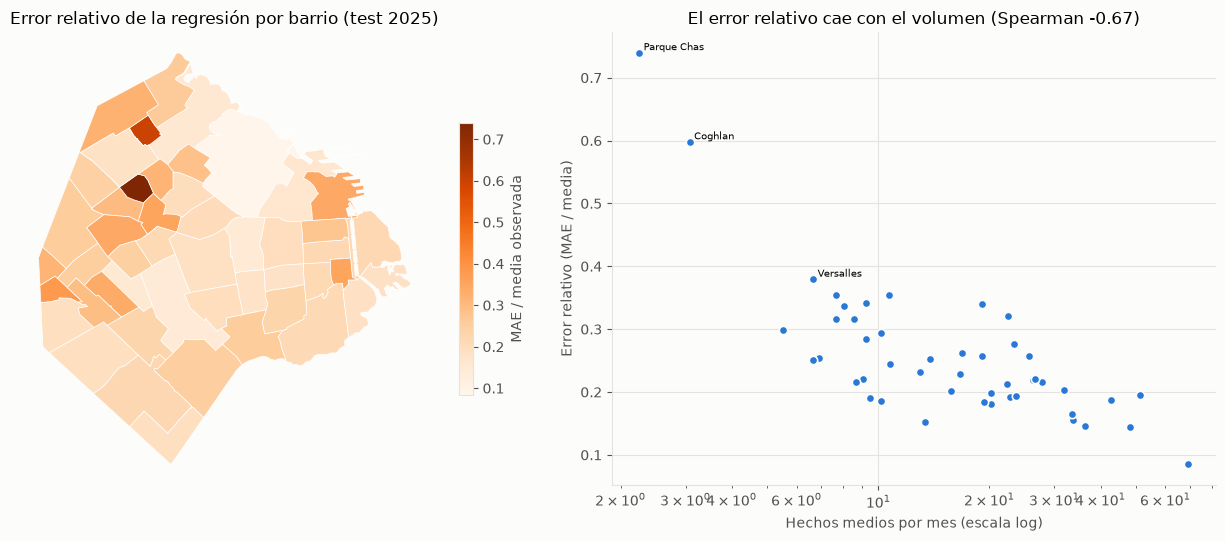

In [9]:
g = gpd.read_file(ROOT / "data/raw/limites/barrios.geojson").rename(columns={"nombre": "barrio"}).merge(eb.reset_index(), on="barrio")
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
g.plot(column="MAE_rel_reg", cmap="Oranges", legend=True, ax=axes[0], edgecolor="white", lw=.5, legend_kwds={"shrink": .6, "label": "MAE / media observada"})
axes[0].set_axis_off(); axes[0].set_title("Error relativo de la regresión por barrio (test 2025)")
axes[1].scatter(eb["y_media"], eb["MAE_rel_reg"], s=36, color=CAT[0], edgecolor=SURFACE, lw=1.2)
axes[1].set_xscale("log"); axes[1].set_xlabel("Hechos medios por mes (escala log)"); axes[1].set_ylabel("Error relativo (MAE / media)")
axes[1].set_title(f"El error relativo cae con el volumen (Spearman {M['sesgos']['spearman_MAE_rel_vs_nivel']:.2f})")
for b in eb["MAE_rel_reg"].nlargest(3).index: axes[1].annotate(b, (eb.loc[b, "y_media"], eb.loc[b, "MAE_rel_reg"]), fontsize=7.5, xytext=(3, 2), textcoords="offset points")
fig.tight_layout(); fig.savefig(FIG / "error_relativo.png", dpi=150); plt.show()

**Lectura (5): sesgos territoriales.**
- **Error relativo.** Es mayor en los barrios de **bajo volumen**: MAE/media de 0,34, frente a 0,19 en los de volumen alto. El modelo y el baseline tienen el mismo patrón, que proviene del ruido de Poisson en conteos chicos, no del modelo.
- **Subestimación.** Se concentra en el **interior central-denso** (sesgo de −2,2 hechos por barrio-mes en 2025).
- **Representación del perfil de borde.** Los barrios del borde (General Paz y autopistas) reúnen el **16,2 % de los hechos**, pero reciben solo el **8,3 %** (clasificador) o el 10 % (historial) de las selecciones del top 10. Su carga está repartida entre 9 barrios de volumen medio: con el historial, solo Saavedra entra con regularidad al top 10 (10 de los 12 meses de 2025), y Liniers y Villa Lugano una vez cada uno. **Es una consecuencia del criterio de priorizar por conteo de barrio, no de los modelos.** Una política orientada a ese perfil necesitaría un criterio propio, por ejemplo por corredores de vías rápidas. La densidad no serviría, porque el borde tiene la menor densidad de hechos. Aquí se midió la participación del grupo de barrios de borde, no la de los hechos ocurridos en vías rápidas (revisión independiente, R3).
- **Calibración por perfil.** El clasificador sobreestima la chance de entrar al top 10 en el borde (0,146 frente a 0,102 observado) y está bien calibrado en el interior (0,302 frente a 0,319, y 0,184 frente a 0,167).

## 6. Exposición por corredor (H8, extensión condicionada, 2024)

Se usan los 95 sensores de 2024 (F07; un miércoles por semana). Para cada ubicación:
- **exposición** = media diaria de vehículos registrados por el sensor × 365. **Corrección (revisión independiente, R1):** cada ubicación registra **un solo sentido** de circulación, aunque 47 de los 95 sensores están en vías de doble mano; no es la suma de ambos sentidos;
- **hechos** = siniestros de 2024 a 150 m o menos del sensor;
- **tasa** = hechos por millón de vehículos registrados en el año (columna `tasa_por_millon_veh`).

Se compara el orden por conteo con el orden por tasa. **No se extrapola** fuera de los corredores medidos.

> **Qué hace la celda siguiente.** Cruza los conteos de tránsito de 2024 de 95 sensores con los hechos ocurridos a 150 m o menos de cada uno, y compara el orden por cantidad de hechos con el orden por tasa por vehículo.

{
 "sensores": 95,
 "spearman_conteo_vs_tasa": 0.676,
 "pct_cambia_cuartil": 43.2,
 "top10_coinciden": 4,
 "spearman_hechos_vs_volumen": 0.032,
 "tasa_por_tipo_via": {
  "Autopista": 1.272,
  "Carriles Exclusivos": 5.429,
  "calle_avenida": 1.878
 }
}


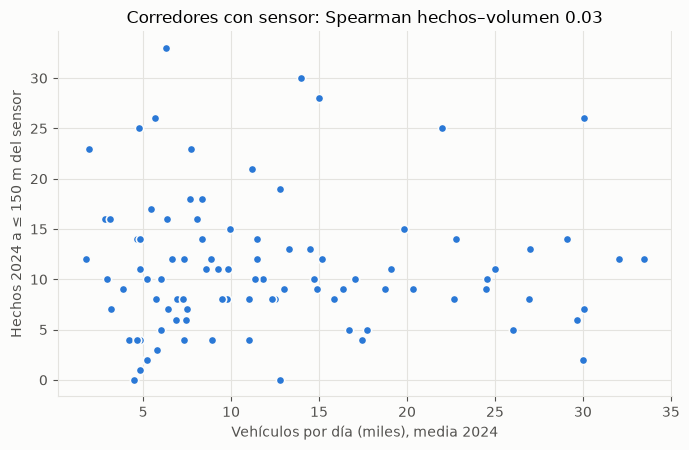

In [10]:
cv = pd.read_excel(ROOT / "data/raw/exposicion/conteo_vehicular_2024.xlsx")
daily = cv.groupby(["ubicacion_conteo", "fecha_conteo"])["conteo_vehiculos"].sum().groupby("ubicacion_conteo").mean()
loc = cv.groupby("ubicacion_conteo")[["longitud_conteo", "latitud_conteo", "especificacion_via_conteos"]].first()
sg = gpd.GeoDataFrame(loc.join(daily.rename("veh_dia")), geometry=gpd.points_from_xy(loc["longitud_conteo"], loc["latitud_conteo"]), crs=4326).to_crs(CRS_CABA)
p24 = pts[pts["anio"] == 2024]
sg["hechos_150m"] = [int(p24.geometry.within(g.buffer(150)).sum()) for g in sg.geometry]
sg["tasa_por_millon_veh"] = sg["hechos_150m"] / (sg["veh_dia"] * 365) * 1e6
ok = sg[sg["veh_dia"] > 0]
rho = stats.spearmanr(ok["hechos_150m"], ok["tasa_por_millon_veh"]).statistic
q_c, q_t = pd.qcut(ok["hechos_150m"].rank(method="first"), 4, labels=False), pd.qcut(ok["tasa_por_millon_veh"].rank(method="first"), 4, labels=False)
top_c, top_t = set(ok["hechos_150m"].nlargest(10).index), set(ok["tasa_por_millon_veh"].nlargest(10).index)
M["exposicion_h8"] = {"sensores": len(ok), "spearman_conteo_vs_tasa": round(float(rho), 3), "pct_cambia_cuartil": round(float((q_c != q_t).mean() * 100), 1),
                      "top10_coinciden": len(top_c & top_t), "spearman_hechos_vs_volumen": round(float(stats.spearmanr(ok["hechos_150m"], ok["veh_dia"]).statistic), 3),
                      "tasa_por_tipo_via": ok.groupby("especificacion_via_conteos")["tasa_por_millon_veh"].median().round(3).to_dict()}
ok.drop(columns="geometry").round(4).to_csv(TAB / "exposicion_corredores_2024.csv"); print(json.dumps(M["exposicion_h8"], indent=1, ensure_ascii=False))
fig, ax = plt.subplots(figsize=(7, 4.6))
ax.scatter(ok["veh_dia"] / 1000, ok["hechos_150m"], s=36, color=CAT[0], edgecolor=SURFACE, lw=1.2)
ax.set_xlabel("Vehículos por día (miles), media 2024"); ax.set_ylabel("Hechos 2024 a ≤ 150 m del sensor")
ax.set_title(f"Corredores con sensor: Spearman hechos–volumen {M['exposicion_h8']['spearman_hechos_vs_volumen']:.2f}")
fig.tight_layout(); fig.savefig(FIG / "exposicion_corredores.png", dpi=150); plt.show()

**Lectura (6, H8 en corredores con sensor, 2024).** Alrededor de los 95 sensores, el **conteo de hechos casi no se relaciona con el volumen vehicular** (Spearman 0,03). El orden por **tasa por vehículo** difiere sustancialmente del orden por conteo:
- Spearman de 0,68 entre ambos órdenes;
- **43 % de los sensores cambia de cuartil**;
- solo 4 de los 10 primeros coinciden.

Las tasas medianas por tipo de vía (5,4 en carriles exclusivos, 1,9 en calles y avenidas y 1,3 en autopistas, por millón de vehículos al año) **no son comparables entre sí**: los sensores de carriles exclusivos parecen contar solo ese carril y registran la mitad de volumen con una cantidad de hechos similar.

**Corrección tras la revisión independiente (R1).** Cada sensor mide un solo sentido y casi la mitad está en vías de doble mano, así que el denominador no es homogéneo. En el subgrupo más homogéneo (34 calles y avenidas de mano única) el reordenamiento persiste: el 44 % cambia de cuartil, aunque con pocas unidades ([evidencia](../docs/evidence/revision_independiente/h8_subgrupos.txt)). **H8 queda como indicativa, no como respaldada**: sugiere que ajustar por tránsito podría cambiar qué lugares parecen críticos, pero no mide riesgo por exposición. **Límites:**
- cada sensor cuenta un solo sentido de circulación;
- solo 2024 y un miércoles por semana;
- un radio de 150 m que incluye calles transversales;
- los sensores no son representativos de los barrios.

**No se extrapola** a toda la ciudad (D8).

## 7. Registro

> **Qué hace la celda siguiente.** Guarda las cifras del notebook en `integrated_metrics.json`. Las tablas, como `cobertura_topk.csv`, ya quedaron guardadas en cada sección. Las usan el informe [docs/robustness_report.md](../docs/robustness_report.md), la web pública y el notebook 07.

In [11]:
(TAB / "integrated_metrics.json").write_text(json.dumps(M, indent=2, ensure_ascii=False, default=str), encoding="utf-8")
print("Guardado:", (TAB / "integrated_metrics.json").relative_to(ROOT))

Guardado: reports\tables\06_integrated_evaluation\integrated_metrics.json


### Conclusiones y qué pasa al paso siguiente

- **Respuesta a la pregunta.** Como herramienta de priorización, ningún modelo supera de forma relevante al promedio de 12 meses: con 10 barrios, ambos reúnen alrededor del 43 % de los hechos del mes siguiente, y el oráculo, que conoce el resultado, llega al 44,6 %. La recomendación práctica es usar el historial, que es simple y transparente.
- **Qué agrega este notebook.** La conclusión resiste todas las sensibilidades. Priorizar por conteo de barrio deja subrepresentado al grupo de barrios de borde. En los corredores con medición, ordenar por tasa por vehículo reordena los puntos, pero como cada sensor mide un solo sentido el resultado es solo indicativo.
- **Límites.** Una temporada de prueba; cobertura no es lo mismo que siniestros evitados; la exposición solo existe en 2024 y en corredores con sensores.
- **Siguiente paso.** El notebook 07 traduce estos resultados para una audiencia no técnica.